In [5]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
from collections import deque
import fifpy

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 25
})

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import gaussian_fft_filter_2d, iterative_filtering1D, iterative_filtering3D
from shared.thickness import gaussian
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("single_sheet", "MagRecEvent")

In [2]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
h = 0.0625

In [4]:
#Lets Computer J_total

# # 1. Read the HDF5 file
File_Bx = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bx_ApJ_t40.h5'  # Replace with your file path
File_By = f'{DATA_ROOT}/beta_p_1/beta_e_1/By_ApJ_t40.h5'  # Replace with your file path
File_Bz = f'{DATA_ROOT}/beta_p_1/beta_e_1/Bz_ApJ_t40.h5'  # Replace with your file path

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy, h5py.File(File_Bz, 'r') as fBz:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    data_Bz = fBz['DS1'][:].T
    data_Bx_filtered = gaussian_fft_filter_2d(data_Bx, k0=0.2 * len(data_Bx))
    data_By_filtered = gaussian_fft_filter_2d(data_By, k0=0.2 * len(data_Bx))
    data_Bz_filtered = gaussian_fft_filter_2d(data_Bz, k0=0.2 * len(data_Bx))
    # data_Bx_filtered, data_By_filtered, data_Bz_filtered = iterative_filtering3D(data_Bx, data_By, data_Bz, 1, Xi=2.0)
    data_Jx = partial_y_fft(data_Bz_filtered,h)
    data_Jy = -partial_x_fft(data_Bz_filtered,h)
    data_Jz = partial_x_fft(data_By_filtered,h)-partial_y_fft(data_Bx_filtered,h)
    # data_Jx = partial_y_fft(data_Bz,h)
    # data_Jy = -partial_x_fft(data_Bz,h)
    # data_Jz = partial_x_fft(data_By,h)-partial_y_fft(data_Bx,h)
    

J_squared = data_Jx**2 + data_Jy**2 + data_Jz**2
# J_squared = gaussian_fft_filter_2d(J_squared, k0=0.2 * len(data_Bx))

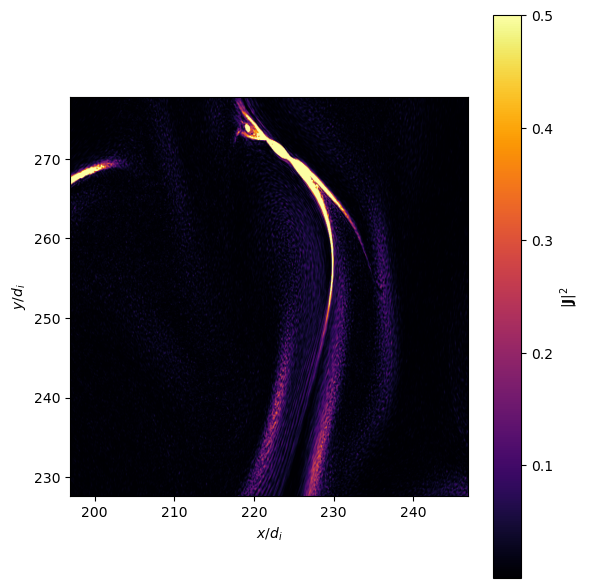

In [5]:
window = 400
x0, y0 = 3550, 4043

# Slice a window around (x0, y0)
patch = J_squared[x0-window:x0+window, y0-window:y0+window]

# Convert grid indices to physical coordinates
extent = [(x0-window)*h, (x0+window)*h,
          (y0-window)*h, (y0+window)*h]

plt.figure(figsize=(6, 6))
plt.imshow(
    patch.T,
    cmap='inferno',
    origin='lower',
    vmax=0.5,
    extent=extent,
)
plt.xlabel(r'$x / d_i$')
plt.ylabel(r'$y / d_i$')
plt.colorbar(label=r'$|\mathbf{J}|^2$')
plt.tight_layout()
plt.savefig(RESULTS / "J2_around_peak.png", dpi=300)
plt.show()

In [18]:
x0, y0 = 3732, 2228

# region ID containing this maximum
region_id = labeled_mask[x0, y0]

region = (labeled_mask == region_id)

In [19]:
dist = ndi.distance_transform_edt(region)

radius = dist.max()
thickness_m1 = 2 * radius

# center of largest inscribed circle
cx, cy = np.unravel_index(np.argmax(dist), dist.shape)

print("Thickness (Method 1) =", thickness_m1, "pixels")
print("Circle center =", (cx, cy))

Thickness (Method 1) = 54.037024344425184 pixels
Circle center = (np.int64(3735), np.int64(2195))


In [20]:
x0, y0 = 3732, 2228
dx, dy = direction

x, y = float(x0), float(y0)
step_size = 1
max_steps = 1000

# --- forward ---
xf, yf = x, y
for _ in range(max_steps):

    xf_new = xf + dx*step_size
    yf_new = yf + dy*step_size

    xi, yi = int(round(xf_new)), int(round(yf_new))

    if xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]:
        break

    if not cleaned_mask[xi, yi]:
        break

    xf, yf = xf_new, yf_new

dist_forward = np.hypot(xf-x, yf-y)

# --- backward ---
xb, yb = x, y
for _ in range(max_steps):

    xb_new = xb - dx*step_size
    yb_new = yb - dy*step_size

    xi, yi = int(round(xb_new)), int(round(yb_new))

    if xi < 0 or yi < 0 or xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]:
        break

    if not cleaned_mask[xi, yi]:
        break

    xb, yb = xb_new, yb_new

dist_backward = np.hypot(xb-x, yb-y)

thickness_m2 = dist_forward + dist_backward

print("Forward distance:", dist_forward)
print("Backward distance:", dist_backward)
print("Thickness (Method 2):", thickness_m2)

Forward distance: 33.99999999999529
Backward distance: 23.999999999996678
Thickness (Method 2): 57.99999999999197


In [21]:
# Gaussian model

# maximum location
x0, y0 = 3732, 2228

# descent direction computed previously
dx, dy = dx, dy  # from your steepest descent computation

# parameters
max_len = 60  # half-length of profile
step_px = 1

# sample profile along steepest descent
xs = []
vals = []

for k in range(-max_len, max_len + 1):
    xc = x0 + k*dx
    yc = y0 + k*dy
    xi = int(round(xc))
    yi = int(round(yc))

    if 0 <= xi < J_squared.shape[0] and 0 <= yi < J_squared.shape[1]:
        xs.append(k)
        vals.append(J_squared[xi, yi])

xs = np.array(xs)
vals = np.array(vals)

# initial guess for Gaussian
A0 = vals.max() - vals.min()
mu0 = xs[np.argmax(vals)]
sigma0 = max_len/4
B0 = vals.min()

# fit Gaussian
popt, pcov = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
A, mu, sigma, B = popt
fwhm = 2 * np.sqrt(2*np.log(2)) * sigma

print("Method 3 FWHM thickness:", fwhm, "pixels")
thickness_m3 = fwhm

Method 3 FWHM thickness: 29.02093379642713 pixels


Y value at FWHM: 0.132


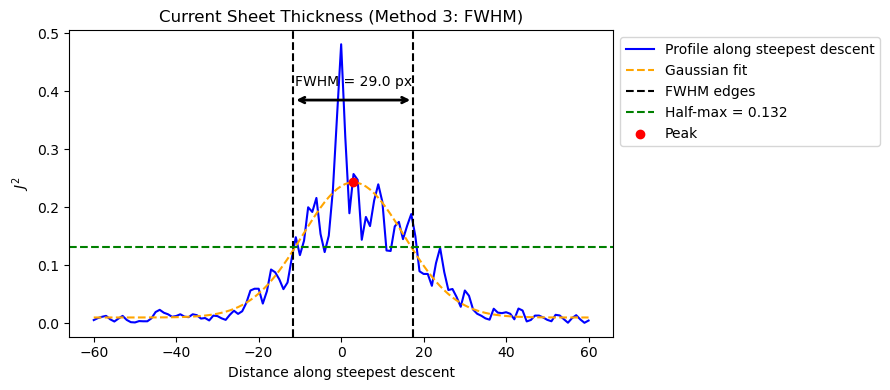

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Gaussian fit values
fit_vals = gaussian(xs, *popt)

# FWHM edges
left = mu - fwhm/2
right = mu + fwhm/2

# Y-value at half maximum
y_half = gaussian(mu, *popt)/2 + popt[3]  # A/2 + B
print(f"Y value at FWHM: {y_half:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(xs, vals, label="Profile along steepest descent", color='blue')
plt.plot(xs, fit_vals, '--', label="Gaussian fit", color='orange')

# Vertical lines at FWHM edges
plt.axvline(left, linestyle='--', color='black', label='FWHM edges')
plt.axvline(right, linestyle='--', color='black')

# Horizontal line at half maximum
plt.axhline(y_half, linestyle='--', color='green', label=f'Half-max = {y_half:.3f}')

# Peak marker
plt.scatter(mu, gaussian(mu,*popt), color='red', zorder=3, label='Peak')

# Arrow showing FWHM
plt.annotate(
    "",
    xy=(right, max(vals)*0.8),
    xytext=(left, max(vals)*0.8),
    arrowprops=dict(arrowstyle="<->", color='black', linewidth=2)
)
plt.text(mu, max(vals)*0.85, f"FWHM = {fwhm:.1f} px", ha='center', color='black')

plt.xlabel("Distance along steepest descent")
plt.ylabel(r"$J^2$")
plt.title("Current Sheet Thickness (Method 3: FWHM)")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(RESULTS / "J2_FWHM.png", dpi=300)
plt.show()

In [23]:
# Maximum location
x0, y0 = 3732, 2228

# Threshold for region growth
J2_thresh_region = 0.005 * np.max(J_squared)

# Initialize empty mask
cs_mask = np.zeros_like(J_squared, dtype=bool)

# Queue for BFS
queue = deque()
queue.append((x0, y0))

# Keep track of visited pixels
visited = np.zeros_like(J_squared, dtype=bool)

# Directions for 4-neighbors (up, down, left, right)
neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Flood-fill / grow the region
while queue:
    x, y = queue.popleft()
    if visited[x, y]:
        continue
    visited[x, y] = True

    # Check threshold
    if J_squared[x, y] >= J2_thresh_region:
        cs_mask[x, y] = True

        # Add 4-neighbors to queue
        for dx, dy in neighbors:
            xn, yn = x + dx, y + dy
            if 0 <= xn < J_squared.shape[0] and 0 <= yn < J_squared.shape[1]:
                if not visited[xn, yn]:
                    queue.append((xn, yn))

# Optional: smooth mask slightly
from skimage import morphology
cs_mask = morphology.binary_opening(cs_mask, morphology.disk(2))
cs_mask = morphology.binary_closing(cs_mask, morphology.disk(2))

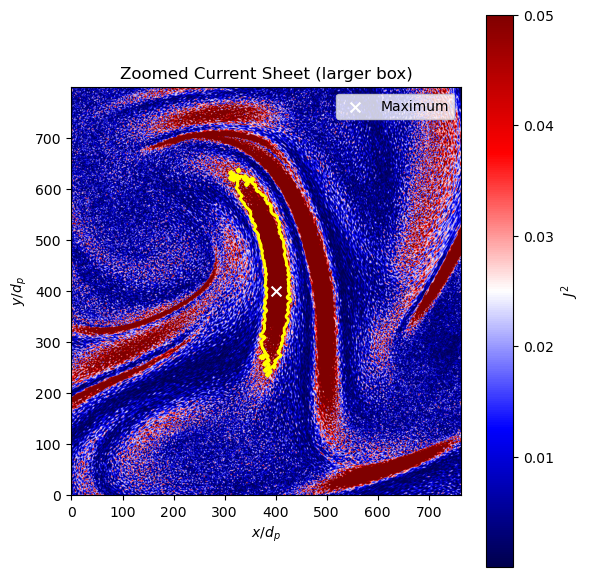

In [24]:
# Zoom box size
half_box = 400  # pixels around the CS bounding box center

# Center of CS
x_center = x0
y_center = y0

# Compute zoom limits
x_min = max(x_center - half_box, 0)
x_max = min(x_center + half_box, J_squared.shape[0])
y_min = max(y_center - half_box, 0)
y_max = min(y_center + half_box, J_squared.shape[1])

# Plot zoomed-in view
plt.figure(figsize=(6,6))
plt.imshow(J_squared.T[y_min:y_max, x_min:x_max], cmap='seismic', origin='lower', vmax=0.05)
plt.colorbar(label=r'$J^2$')

# Overlay CS contour (shifted to zoomed frame)
contour = measure.find_contours(cs_mask.T, level=0.5)
for c in contour:
    plt.plot(c[:,1]-x_min, c[:,0]-y_min, color='yellow', linewidth=2)

# Mark maximum (shifted)
plt.scatter(y0 - y_min, x0 - x_min, color='white', marker='x', s=50, label='Maximum')

plt.title("Zoomed Current Sheet (larger box)")
plt.xlabel(r"$x/d_p$")
plt.ylabel(r"$y/d_p$")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "J2_M4_Single_Sheet_Threshold_Filter.png", dpi=300)
plt.show()

In [25]:
len(contour)

8

In [26]:
x0, y0 = 3732, 2228
dx, dy = direction

x, y = float(x0), float(y0)
step_size = 1
max_steps = 1000

# --- forward ---
xf, yf = x, y
for _ in range(max_steps):

    xf_new = xf + dx*step_size
    yf_new = yf + dy*step_size

    xi, yi = int(round(xf_new)), int(round(yf_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xf, yf = xf_new, yf_new

dist_forward = np.hypot(xf-x, yf-y)

# --- backward ---
xb, yb = x, y
for _ in range(max_steps):

    xb_new = xb - dx*step_size
    yb_new = yb - dy*step_size

    xi, yi = int(round(xb_new)), int(round(yb_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xb, yb = xb_new, yb_new

dist_backward = np.hypot(xb-x, yb-y)

thickness_m4 = dist_forward + dist_backward

print("Forward distance:", dist_forward)
print("Backward distance:", dist_backward)
print("Thickness (Method 4):", thickness_m2)

Forward distance: 27.999999999996124
Backward distance: 17.99999999999751
Thickness (Method 4): 57.99999999999197


In [27]:
# Maximum location
x0, y0 = 3732, 2228

# Threshold for region growth
J2_thresh_region_m5 = 0.1 * J_squared[3732, 2228]

# Initialize empty mask
cs_mask = np.zeros_like(J_squared, dtype=bool)

# Queue for BFS
queue = deque()
queue.append((x0, y0))

# Keep track of visited pixels
visited = np.zeros_like(J_squared, dtype=bool)

# Directions for 4-neighbors (up, down, left, right)
neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Flood-fill / grow the region
while queue:
    x, y = queue.popleft()
    if visited[x, y]:
        continue
    visited[x, y] = True

    # Check threshold
    if J_squared[x, y] >= J2_thresh_region_m5:
        cs_mask[x, y] = True

        # Add 4-neighbors to queue
        for dx, dy in neighbors:
            xn, yn = x + dx, y + dy
            if 0 <= xn < J_squared.shape[0] and 0 <= yn < J_squared.shape[1]:
                if not visited[xn, yn]:
                    queue.append((xn, yn))

# Optional: smooth mask slightly
from skimage import morphology
cs_mask = morphology.binary_opening(cs_mask, morphology.disk(2))
cs_mask = morphology.binary_closing(cs_mask, morphology.disk(2))

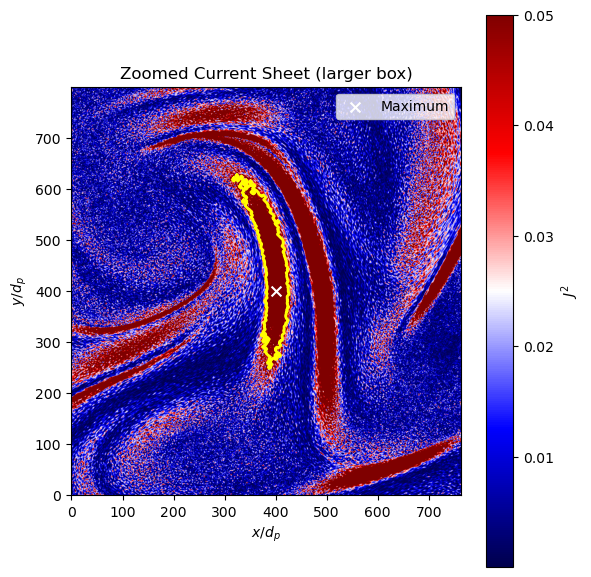

In [28]:
# Zoom box size
half_box = 400  # pixels around the CS bounding box center

# Center of CS
x_center = x0
y_center = y0

# Compute zoom limits
x_min = max(x_center - half_box, 0)
x_max = min(x_center + half_box, J_squared.shape[0])
y_min = max(y_center - half_box, 0)
y_max = min(y_center + half_box, J_squared.shape[1])

# Plot zoomed-in view
plt.figure(figsize=(6,6))
plt.imshow(J_squared.T[y_min:y_max, x_min:x_max], cmap='seismic', origin='lower', vmax=0.05)
plt.colorbar(label=r'$J^2$')

# Overlay CS contour (shifted to zoomed frame)
contour = measure.find_contours(cs_mask.T, level=0.5)
for c in contour:
    plt.plot(c[:,1]-x_min, c[:,0]-y_min, color='yellow', linewidth=2)

# Mark maximum (shifted)
plt.scatter(y0 - y_min, x0 - x_min, color='white', marker='x', s=50, label='Maximum')

plt.title("Zoomed Current Sheet (larger box)")
plt.xlabel(r"$x/d_p$")
plt.ylabel(r"$y/d_p$")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "J2_M5_Single_Sheet_Threshold.png", dpi=300)
plt.show()

In [29]:
x0, y0 = 3732, 2228
dx, dy = direction

x, y = float(x0), float(y0)
step_size = 1
max_steps = 1000

# --- forward ---
xf, yf = x, y
for _ in range(max_steps):

    xf_new = xf + dx*step_size
    yf_new = yf + dy*step_size

    xi, yi = int(round(xf_new)), int(round(yf_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xf, yf = xf_new, yf_new

dist_forward = np.hypot(xf-x, yf-y)

# --- backward ---
xb, yb = x, y
for _ in range(max_steps):

    xb_new = xb - dx*step_size
    yb_new = yb - dy*step_size

    xi, yi = int(round(xb_new)), int(round(yb_new))

    if xi < 0 or yi < 0 or xi >= cs_mask.shape[0] or yi >= cs_mask.shape[1]:
        break

    if not cs_mask[xi, yi]:
        break

    xb, yb = xb_new, yb_new

dist_backward = np.hypot(xb-x, yb-y)

thickness_m5 = dist_forward + dist_backward

print("Forward distance:", dist_forward)
print("Backward distance:", dist_backward)
print("Thickness (Method 5):", thickness_m2)

Forward distance: 25.999999999996398
Backward distance: 17.99999999999751
Thickness (Method 5): 57.99999999999197


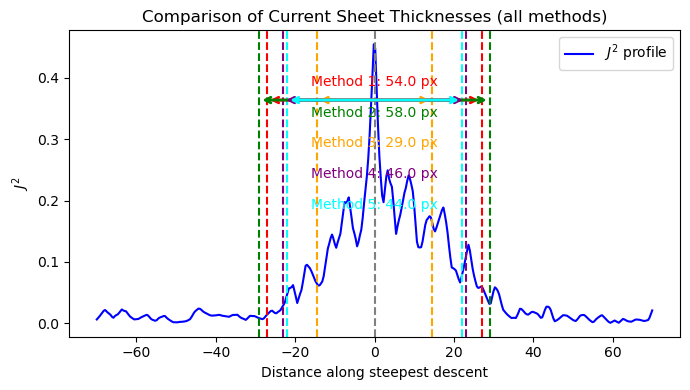

In [30]:
# Distance along the line
L = 70
s = np.linspace(-L, L, 400)

# Coordinates along the steepest descent
x_line = x0 + s*dx
y_line = y0 + s*dy

# Interpolate J^2 along the line
profile = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(7,4))
plt.plot(s, profile, label=r"$J^2$ profile", color='blue')
plt.axvline(0, linestyle='--', color='gray')

# --- Overlay thicknesses ---
methods = {
    'Method 1': thickness_m1,
    'Method 2': thickness_m2,
    'Method 3': thickness_m3,
    'Method 4': thickness_m4,
    'Method 5': thickness_m5
}

colors = ['red', 'green', 'orange', 'purple', 'cyan']

for (name, thick), color in zip(methods.items(), colors):
    half = thick / 2
    plt.axvline(-half, linestyle='--', color=color)
    plt.axvline(half, linestyle='--', color=color)
    plt.annotate(
        "",
        xy=(half, profile.max()*0.8),
        xytext=(-half, profile.max()*0.8),
        arrowprops=dict(arrowstyle="<->", color=color, linewidth=2)
    )
    plt.text(0, profile.max()*0.85 - 0.05*list(methods.keys()).index(name),
             f"{name}: {thick:.1f} px",
             color=color, ha='center')

plt.xlabel("Distance along steepest descent")
plt.ylabel(r"$J^2$")
plt.title("Comparison of Current Sheet Thicknesses (all methods)")
plt.legend()
plt.tight_layout()
plt.show()

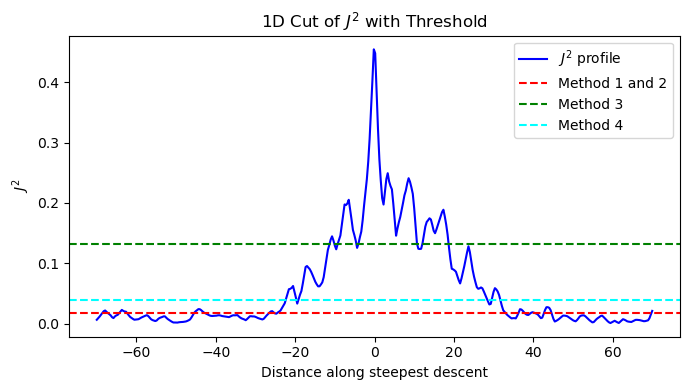

In [31]:
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
import numpy as np

# Distance along the cut
L = 70
s = np.linspace(-L, L, 400)

# Coordinates along the steepest descent
x_line = x0 + s*dx
y_line = y0 + s*dy

# Interpolate J^2 along the line
profile = map_coordinates(J_squared, [x_line, y_line], order=1)

plt.figure(figsize=(7,4))
plt.plot(s, profile, label=r"$J^2$ profile", color='blue')

# Vertical line at threshold
plt.axhline(threshold, color='red', linestyle='--', label='Method 1 and 2')
plt.axhline(y_half, color='green', linestyle='--', label='Method 3')
plt.axhline(J2_thresh_region, color='cyan', linestyle='--', label='Method 4')
# plt.axhline(J2_thresh_region_m5, color='pink', linestyle='--', label='Method 5')



plt.xlabel("Distance along steepest descent")
plt.ylabel(r"$J^2$")
plt.title("1D Cut of $J^2$ with Threshold")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "J2_Threshold_Comparison.png", dpi=300)
plt.show()

Computing 151 patches across 128 workers ...
t=16: done
t=1: done
t=109: done
t=75: done
t=11: done
t=60: done
t=20: done
t=121: done
t=12: done
t=24: done
t=38: done
t=14: done
t=88: done
t=123: done
t=84: done
t=35: done
t=126: done
t=50: done
t=13: done
t=31: done
t=30: done
t=125: done
t=96: done
t=117: done
t=36: done
t=62: done
t=29: done
t=77: done
t=85: done
t=115: done
t=78: done
t=91: done
t=10: done
t=112: done
t=76: done
t=124: done
t=61: done
t=93: done
t=70: done
t=110: done
t=92: done
t=28: done
t=95: done
t=59: done
t=22: done
t=25: done
t=63: done
t=3: done
t=26: done
t=82: done
t=68: done
t=114: done
t=8: done
t=72: done
t=111: done
t=89: done
t=15: done
t=54: done
t=33: done
t=55: done
t=80: done
t=44: done
t=18: done
t=46: done
t=49: done
t=98: done
t=119: done
t=69: done
t=67: done
t=47: done
t=6: done
t=87: done
t=105: done
t=101: done
t=65: done
t=5: done
t=79: done
t=64: done
t=32: done
t=34: done
t=73: done
t=122: done
t=53: done
t=94: done
t=41: done
t=66: don

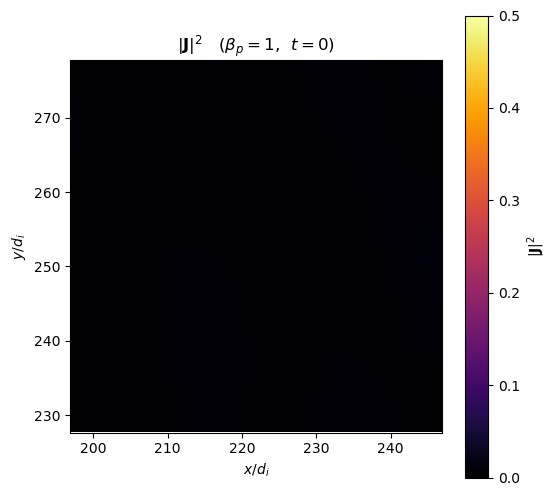

In [6]:
# ================================================================
#  Animation of the |J|^2 patch around a fixed point, t = 0 .. 150
#  ------------------------------------------------------------
#  Per snapshot: load B, Gaussian-filter, J = curl(B_filtered), |J|^2,
#  then cut the same window around (x0, y0). Frames are computed in
#  parallel (the full-field filtering is the expensive part), then the
#  small patches are animated with a fixed colour scale.
#
#  Needs from your session: gaussian_fft_filter_2d, partial_x_fft,
#                           partial_y_fft, and the grid spacing h
# ================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import h5py
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

# ---------- settings ----------
beta      = 1
times     = range(0, 151)                  # t = 0 .. 150
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
out_file  = str(RESULTS / "J2_patch_animation.mp4")
fps       = 12

x0, y0    = 3550, 4043                      # patch centre (grid indices)
window    = 400                             # half-width of the patch (px)
k0_frac   = 0.2                             # Gaussian filter cutoff = k0_frac * Nx
vmax      = 0.5                             # colour scale (as in your still)

# each worker loads the FULL (large) field, so memory ~ N_WORKERS * a few hundred MB.
# lower this if you hit memory limits; raise it if you have headroom.
N_WORKERS = 128
THREADS_PER_WORKER = 1


def _init_worker(n):
    if threadpool_limits is not None:
        threadpool_limits(n)


# ---------- one snapshot -> (t, |J|^2 patch) ----------
def compute_patch(t):
    def load(tag):
        with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
            return f["DS1"][:].T

    Bx, By, Bz = load("Bx"), load("By"), load("Bz")
    k0 = k0_frac * len(Bx)
    Bxf = gaussian_fft_filter_2d(Bx, k0=k0)
    Byf = gaussian_fft_filter_2d(By, k0=k0)
    Bzf = gaussian_fft_filter_2d(Bz, k0=k0)

    Jx =  partial_y_fft(Bzf, h)
    Jy = -partial_x_fft(Bzf, h)
    Jz =  partial_x_fft(Byf, h) - partial_y_fft(Bxf, h)
    J2 = np.mod(Jz)

    return t, J2[x0 - window:x0 + window, y0 - window:y0 + window]


# ---------- compute every patch (parallel over time) ----------
patches = []                                # each: (t, patch)
task_times = list(times)

if N_WORKERS == 1:
    for t in task_times:
        try:
            patches.append(compute_patch(t)); print(f"t={t}: done", flush=True)
        except FileNotFoundError:
            print(f"t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Computing {len(task_times)} patches across {N_WORKERS} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(compute_patch, t): t for t in task_times}
        for fut in as_completed(futs):
            t = futs[fut]
            try:
                patches.append(fut.result()); print(f"t={t}: done", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)

if not patches:
    raise SystemExit("No patches computed (check paths / times).")
patches.sort(key=lambda p: p[0])            # time order


# ---------- animate ----------
extent = [(x0 - window) * h, (x0 + window) * h,
          (y0 - window) * h, (y0 + window) * h]

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(patches[0][1].T, cmap="inferno", origin="lower",
               vmin=0, vmax=vmax, extent=extent)
fig.colorbar(im, label=r"$|\mathbf{J}|^2$")
ax.set_xlabel(r"$x / d_i$")
ax.set_ylabel(r"$y / d_i$")


def update(i):
    t, patch = patches[i]
    im.set_data(patch.T)
    ax.set_title(rf"$|\mathbf{{J}}|^2$   ($\beta_p={beta}$,  $t={t}$)")
    return [im]


anim = FuncAnimation(fig, update, frames=len(patches), interval=1000 / fps)
anim.save(out_file, writer="ffmpeg", fps=fps)
print(f"saved {out_file}")

Computing 151 patches across 128 workers ...
t=45: done
t=127: done
t=123: done
t=108: done
t=44: done
t=27: done
t=18: done
t=17: done
t=118: done
t=117: done
t=37: done
t=7: done
t=89: done
t=126: done
t=85: done
t=111: done
t=24: done
t=49: done
t=97: done
t=43: done
t=107: done
t=114: done
t=81: done
t=119: done
t=48: done
t=109: done
t=116: done
t=55: done
t=113: done
t=63: done
t=1: done
t=112: done
t=3: done
t=36: done
t=110: done
t=93: done
t=58: done
t=51: done
t=104: done
t=88: done
t=46: done
t=96: done
t=26: done
t=64: done
t=6: done
t=92: done
t=56: done
t=74: done
t=79: done
t=32: done
t=19: done
t=105: done
t=0: done
t=50: done
t=41: done
t=80: done
t=54: done
t=62: done
t=29: done
t=76: done
t=39: done
t=9: done
t=15: done
t=98: done
t=53: done
t=59: done
t=91: done
t=47: done
t=95: done
t=75: done
t=77: done
t=100: done
t=11: done
t=72: done
t=83: done
t=78: done
t=33: done
t=61: done
t=30: done
t=66: done
t=122: done
t=8: done
t=90: done
t=86: done
t=68: done
t=12: do

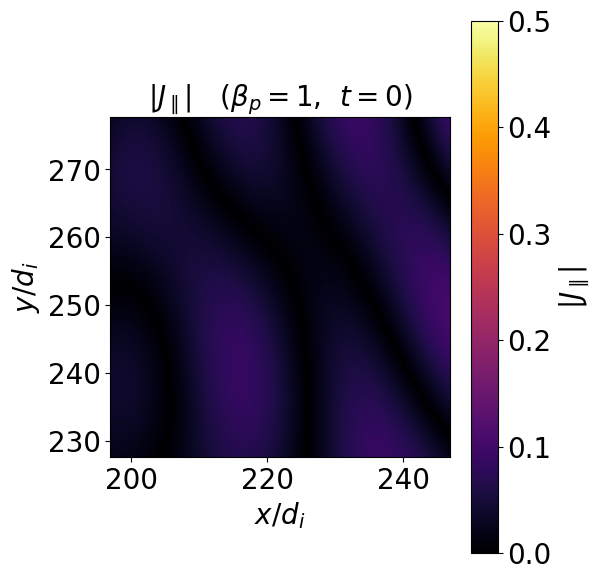

In [7]:
# ================================================================
#  Animation of the |Jz| patch around a fixed point, t = 0 .. 150
#  ------------------------------------------------------------
#  Per snapshot: load Bx, By, Gaussian-filter, Jz = curl of filtered B,
#  |Jz|, then cut the same window around (x0, y0). Frames are computed
#  in parallel (the full-field filtering is the expensive part), then
#  the small patches are animated with a fixed colour scale.
#
#  Needs from your session: gaussian_fft_filter_2d, partial_x_fft,
#                           partial_y_fft, and the grid spacing h
# ================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import h5py
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

# ---------- settings ----------
beta      = 1
times     = range(0, 151)                  # t = 0 .. 150
base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"
out_file  = str(RESULTS / "Jz_patch_animation.mp4")
fps       = 12

x0, y0    = 3550, 4043                      # patch centre (grid indices)
window    = 400                             # half-width of the patch (px)
k0_frac   = 0.2                             # Gaussian filter cutoff = k0_frac * Nx
vmax      = 0.5                             # colour scale for |Jz| (revisit: |Jz| is linear,
                                            #   not the old |J|^2, so the scale differs)

# each worker loads the full Bx, By fields, so memory ~ N_WORKERS * a few hundred MB.
# lower this if you hit memory limits; raise it if you have headroom.
N_WORKERS = 128
THREADS_PER_WORKER = 1


def _init_worker(n):
    if threadpool_limits is not None:
        threadpool_limits(n)


# ---------- one snapshot -> (t, |Jz| patch) ----------
def compute_patch(t):
    def load(tag):
        with h5py.File(f"{base_path}{tag}_ApJ_t{t}.h5", "r") as f:
            return f["DS1"][:].T

    Bx, By = load("Bx"), load("By")
    k0 = k0_frac * len(Bx)
    Bxf = gaussian_fft_filter_2d(Bx, k0=k0)
    Byf = gaussian_fft_filter_2d(By, k0=k0)

    Jz = partial_x_fft(Byf, h) - partial_y_fft(Bxf, h)
    J2 = np.abs(Jz)                          # |Jz|  (modulus of the parallel current)

    return t, J2[x0 - window:x0 + window, y0 - window:y0 + window]


# ---------- compute every patch (parallel over time) ----------
patches = []                                # each: (t, patch)
task_times = list(times)

if N_WORKERS == 1:
    for t in task_times:
        try:
            patches.append(compute_patch(t)); print(f"t={t}: done", flush=True)
        except FileNotFoundError:
            print(f"t={t}: missing file, skipped", flush=True)
else:
    ctx = mp.get_context("fork")
    print(f"Computing {len(task_times)} patches across {N_WORKERS} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(compute_patch, t): t for t in task_times}
        for fut in as_completed(futs):
            t = futs[fut]
            try:
                patches.append(fut.result()); print(f"t={t}: done", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)

if not patches:
    raise SystemExit("No patches computed (check paths / times).")
patches.sort(key=lambda p: p[0])            # time order


# ---------- animate ----------
extent = [(x0 - window) * h, (x0 + window) * h,
          (y0 - window) * h, (y0 + window) * h]

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(patches[0][1].T, cmap="inferno", origin="lower",
               vmin=0, vmax=vmax, extent=extent)
fig.colorbar(im, label=r"$|J_\parallel|$")
ax.set_xlabel(r"$x / d_i$")
ax.set_ylabel(r"$y / d_i$")
fig.tight_layout(pad=0.5)                    # trim the white border (lower pad = tighter)


def update(i):
    t, patch = patches[i]
    im.set_data(patch.T)
    ax.set_title(rf"$|J_\parallel|$   ($\beta_p={beta}$,  $t={t}$)")
    return [im]


anim = FuncAnimation(fig, update, frames=len(patches), interval=1000 / fps)
anim.save(out_file, writer="ffmpeg", fps=fps)
print(f"saved {out_file}")